# Droogte: does a soil-moisture bucket help Pastas in the 2026 drought?

**Local notebook** (research; plan `docs/experiments/PLAN_drought.md`, log `docs/experiments/2026-11-24_drought.md`).

**The question.** In July 2026 (5 mm of rain, 114 mm Makkink) many models stayed too high. An example is BE_0072_BUKR_PB2: observed −0.38 m from June to the end of July, simulated −0.11 m.
Can a drought indicator or soil-moisture bucket help, while the return periods stay computable from IMPREX?

**Why a linear Pastas model misses it.** The deterministic part is not autoregressive. It is a convolution of P and E with a response function, with one gain per mm, the same in a wet January as in a dry July.
The AR part is only a noise model, and our fits run without one. A drought where the soil dries out, ET falls, or the aquifer responds more strongly is non-linear, so a linear model compromises with the winter.

**The candidates.** Each is an extra stress `StressModel(indicator, Exponential, up=None)` with a free sign, built from P and E alone, so it is rebuilt for every IMPREX member:
* `def<D0>`: the KNMI potential precipitation deficit (from 1 April) above D0 mm;
* `roll<days>`: E − P over the last 30, 60 or 90 days, dry side only;
* `bkt<Smax>l<lp>`: the deficit of a root-zone bucket (Smax in mm, ET reduced below lp·Smax).

**Code.** `research/accepted/drought.py` (the indicators), `variants.py` / `run_variants.py` (the fits, nested on the model without the term), `compare_drought.py` (the tables).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PASTAS = Path.cwd().resolve()
while not (PASTAS / "research").is_dir():
    PASTAS = PASTAS.parent
for p in (PASTAS, PASTAS / "src"):
    sys.path.insert(0, str(p))
from research import data
from research.accepted import drought

RESULTS = PASTAS / "research" / "accepted" / "results"
RUN = PASTAS / "local_runs" / "research" / "drought"   # the .pas files (local only)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
radar = pd.read_csv(PASTAS / "data" / "forcing" / "radar_forcing_beemster.csv", parse_dates=["date"], index_col="date")

## 1. The three indicators in 2025–2026 (Beemster radar)
The KNMI deficit resets on 1 April and stays at 0 in winter. The rolling sum forgets after its window. The bucket refills only with rain, and drains slower as it dries (lp).

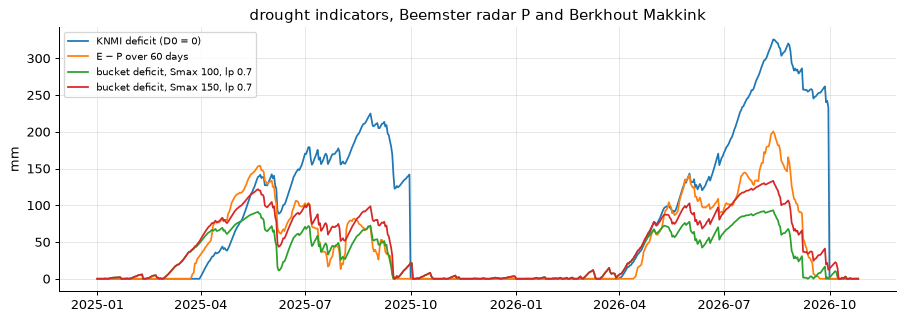

In [2]:
p, e = radar["precipitation_mm"], radar["makkink_mm"]
window = slice("2025-01-01", "2026-10-31")
fig, ax = plt.subplots(figsize=(12, 3.8))
for part, label in (("def0", "KNMI deficit (D0 = 0)"), ("roll60", "E − P over 60 days"),
                    ("bkt100l7", "bucket deficit, Smax 100, lp 0.7"), ("bkt150l7", "bucket deficit, Smax 150, lp 0.7")):
    ax.plot(drought.from_part(part, p, e).loc[window], label=label, lw=1.4)
ax.set_ylabel("mm"); ax.legend(fontsize=8); ax.set_title("drought indicators, Beemster radar P and Berkhout Makkink")
plt.show()

## 2. The example: BE_0072_BUKR_PB2 (filter −7 to −8 m NAP)
The reference pick against the same model type with the bucket (`bkt150l7`). This needs the local run folder.

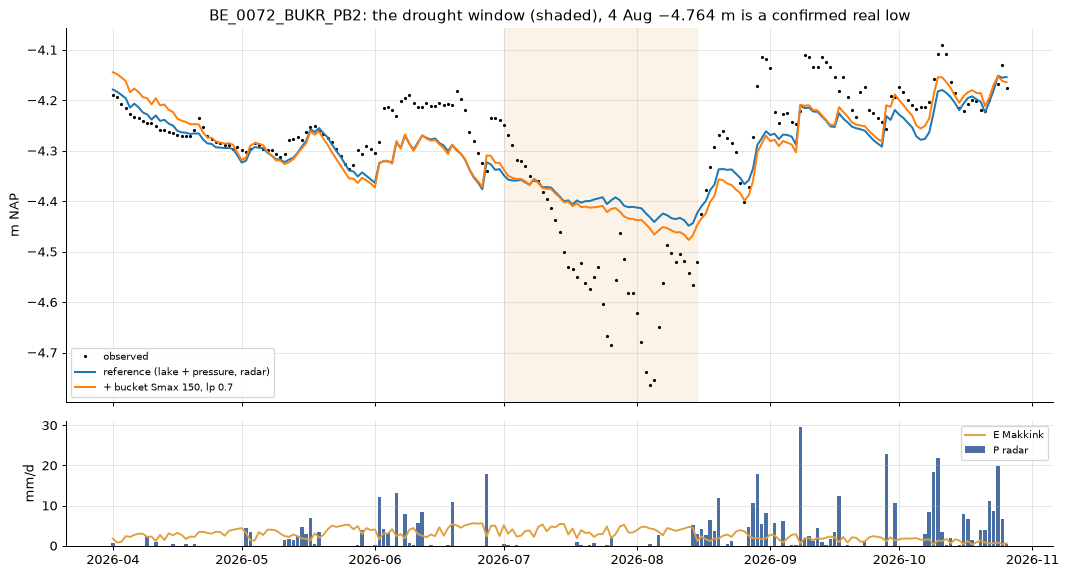

In [3]:
import pastas as ps

stem = "series_54000af8f5d1826b02e295b9_linear_dexp@radar+wl1+baro"
models = {"reference (lake + pressure, radar)": RUN / "models" / f"{stem}.pas",
          "+ bucket Smax 150, lp 0.7": RUN / "models" / f"{stem}+bkt150l7.pas"}
if all(path.exists() for path in models.values()):
    loaded = {k: ps.io.load(str(v)) for k, v in models.items()}
    head = next(iter(loaded.values())).oseries.series
    fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    show = slice("2026-04-01", "2026-10-26")
    axes[0].plot(head.loc[show], "k.", ms=3, label="observed")
    for label, model in loaded.items():
        axes[0].plot(model.simulate(tmin="2024-10-31", tmax="2026-10-26").loc[show], lw=1.6, label=label)
    axes[0].axvspan(pd.Timestamp("2026-07-01"), pd.Timestamp("2026-08-15"), color="#e09f3e", alpha=0.12)
    axes[0].set_ylabel("m NAP"); axes[0].legend(fontsize=8)
    axes[0].set_title("BE_0072_BUKR_PB2: the drought window (shaded), 4 Aug −4.764 m is a confirmed real low")
    axes[1].bar(p.loc[show].index, p.loc[show], color="#4a6fa5", label="P radar")
    axes[1].plot(e.loc[show], color="#e09f3e", label="E Makkink")
    axes[1].set_ylabel("mm/d"); axes[1].legend(fontsize=8)
    fig.tight_layout(); plt.show()
else:
    print("local run folder not found: run research/accepted/run_variants.py first")

## 3. Deep and shallow at the same cross-section
The deep filters (PB2, about −7 m) fell three times more than the shallow PB1 (−3.4 m). Soil moisture alone damps out with depth, so another driver acts on the deep aquifer.

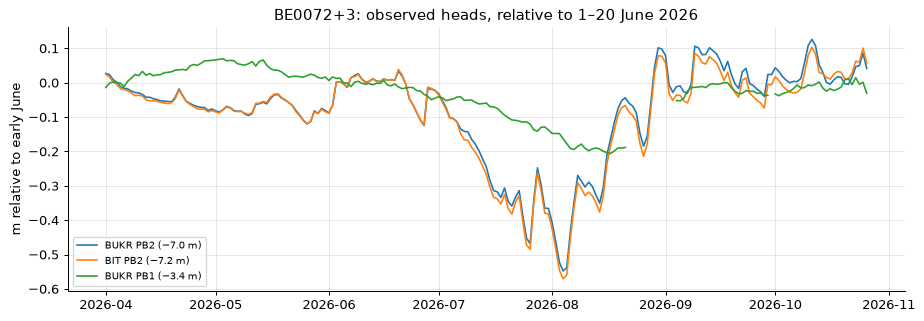

In [4]:
sims = pd.read_parquet(PASTAS / "results_export" / "valid_pastas" / "simulations.parquet",
                       columns=["meetreeks_id", "model_type", "datum", "observed"])
ids = {"BUKR PB2 (−7.0 m)": "54000af8", "BIT PB2 (−7.2 m)": None, "BUKR PB1 (−3.4 m)": "e58f8665"}
objects = pd.read_csv(PASTAS.parent / "data_validation" / "input_output" / "output_databricks" / "metadata" / "object_data.csv")
bit = objects[objects["meetlocatie_code"].str.contains("BE0072\\+3_BIT", na=False)]["meetreeks_id"]
ids["BIT PB2 (−7.2 m)"] = bit.iloc[0][:8] if len(bit) else None
fig, ax = plt.subplots(figsize=(12, 3.8))
for label, prefix in ids.items():
    if prefix is None:
        continue
    one = sims[sims["meetreeks_id"].str.startswith(prefix)]
    one = one[one["model_type"] == one["model_type"].iloc[0]].set_index("datum")["observed"].sort_index()
    one.index = pd.to_datetime(one.index)
    one = one.loc["2026-04-01":"2026-10-26"]
    ax.plot(one - one.loc["2026-06-01":"2026-06-20"].mean(), label=label, lw=1.3)
ax.set_ylabel("m relative to early June"); ax.legend(fontsize=8)
ax.set_title("BE0072+3: observed heads, relative to 1–20 June 2026")
plt.show()

## 4. Like for like: each drought model against the same model without it
Same series, same base type, same forcing. The **left-out RMSE** is the strict test: refit with June–September 2026 masked, then predict the drought.
Negative = better.

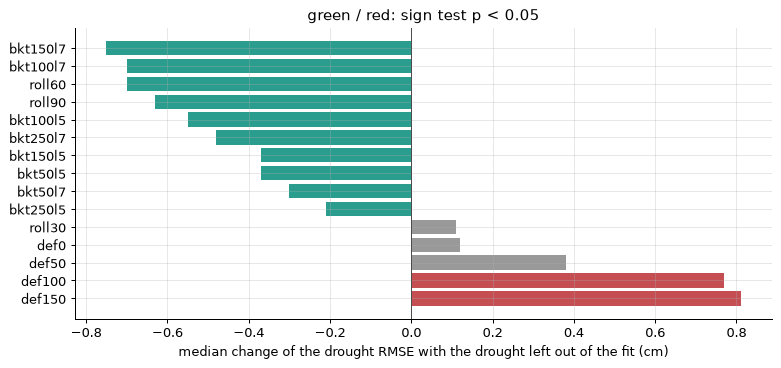

,indicator,models,types,d_aic_median,d_rmse_drought_cm,d_rmse_left_out_cm,left_out_better,left_out_worse,p_left_out,d_r2_holdout_median
0,bkt150l7,1062,6,-118.0,-0.65,-0.75,640,398,0.0000,0.070
1,bkt100l7,1062,6,-110.1,-0.66,-0.70,658,380,0.0000,0.050
2,roll60,267,3,-87.5,-0.46,-0.70,161,99,0.0001,-0.004
3,roll90,267,3,-65.8,-0.43,-0.63,159,101,0.0004,-0.001
4,bkt100l5,267,3,-85.5,-0.36,-0.55,177,83,0.0000,0.044
5,bkt250l7,267,3,-94.6,-0.29,-0.48,159,101,0.0004,0.033
6,bkt150l5,267,3,-96.9,-0.29,-0.37,158,103,0.0008,0.026
7,bkt50l5,267,3,-75.8,-0.50,-0.37,170,90,0.0000,0.019
8,bkt50l7,267,3,-68.7,-0.68,-0.30,160,100,0.0002,0.016
9,bkt250l5,267,3,-83.4,-0.22,-0.21,148,113,0.0351,0.011


In [5]:
paired = pd.read_csv(RESULTS / "drought_paired.csv")
fig, ax = plt.subplots(figsize=(10, 4.2))
order = paired.sort_values("d_rmse_left_out_cm")
colours = ["#2a9d8f" if v < 0 and p < 0.05 else ("#c44e52" if v > 0 and p < 0.05 else "0.6")
           for v, p in zip(order["d_rmse_left_out_cm"], order["p_left_out"])]
ax.barh(order["indicator"], order["d_rmse_left_out_cm"], color=colours)
ax.axvline(0, color="0.3", lw=0.8); ax.invert_yaxis()
ax.set_xlabel("median change of the drought RMSE with the drought left out of the fit (cm)")
ax.set_title("green / red: sign test p < 0.05")
plt.show()
paired[["indicator", "models", "types", "d_aic_median", "d_rmse_drought_cm", "d_rmse_left_out_cm",
        "left_out_better", "left_out_worse", "p_left_out", "d_r2_holdout_median"]]

## 5. With the pipeline's selection and the IMPREX extremes
The reference is the pipeline's extended set (lake + pressure, Berkhout or radar). Each scenario adds one bucket setting for every series, and the selection is `select_models` with the runaway rule.

In [6]:
pd.read_csv(RESULTS / "drought_extremes.csv")

,scenario,passed,gained,lost,p,runaway_picks,runaway_models_avoided,picks_with_indicator,r2_holdout_median,share_dry_T100_below_record_low,dry_T100_minus_record_low_median_cm
0,reference,60,0,0,1.0000,0,4,0,0.483,0.20,4.5
1,bkt100l7,64,4,0,0.1250,0,8,61,0.483,0.19,4.7
2,bkt150l7,65,5,0,0.0625,0,5,61,0.483,0.22,4.2


## 6. Where it still fails: the deep Beemster filters

In [7]:
series = pd.read_csv(RESULTS / "drought_series.csv")
filters = objects.drop_duplicates("meetreeks_id").set_index("meetreeks_id")["begin_filter"]
series["deep"] = series["meetreeks_id"].map(filters) <= -6
table = series.groupby(["polder", "deep"]).agg(series=("meetreeks_id", "size"), misfits=("misfit", "sum"),
                                               drop_error_ref_cm=("ref_drop_error", "median"),
                                               drop_error_bucket_cm=("new_drop_error", "median"))
table[["drop_error_ref_cm", "drop_error_bucket_cm"]] *= 100
table.round(1)

series  misfits  drop_error_ref_cm  drop_error_bucket_cm
polder   deep                                                           
Beemster False      27        2                1.2                   0.1
         True       13        5                5.2                   4.2
Purmer   False      43        1                0.5                   0.5
         True        5        0                0.9                   0.9

## Conclusions
* **The bucket (lp 0.7, Smax 100–150 mm) generalises.**
  * On all 1,062 like-for-like models it lowers the drought RMSE with the drought left out of the fit: 640 better against 398 worse (p < 0.0001).
  * The holdout R² rises by a median of +0.07.
* **The KNMI deficit with a threshold overfits.** Its in-sample fit is best, but out of sample it is worse (D0 100/150). That is the risk of one drought in a two-year record.
* **With the selection and IMPREX:** 60 → 65 passed (bkt150l7), none lost, no runaway picks, and 61 of 89 picks use the bucket.
* **Not solved: the deep Beemster filters.** 5 of 13 there remain strong drought misfits (median drop error 5 cm; the example 24 cm).
  * P and E cannot explain their extra drop, which grows with depth and recovers within days of rain.
  * A non-weather driver is more likely: groundwater abstraction or sprinkling. That needs data (permits, pumping records), not another indicator.